In [1]:
import pandas as pd
import numpy as np

# Load the Iris dataset
df = pd.read_csv("iris.csv")

# Display first 5 rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Statistical Summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


Matplotlib is building the font cache; this may take a moment.


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


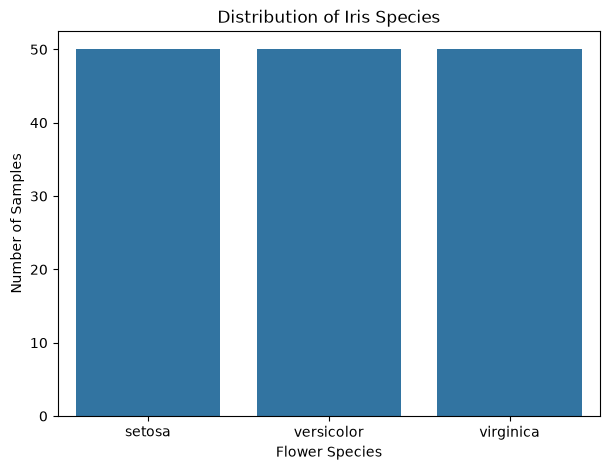

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the number of flowers in each species
print(df['species'].value_counts())

# Visualize species distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='species')

plt.title("Distribution of Iris Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Samples")

plt.show()

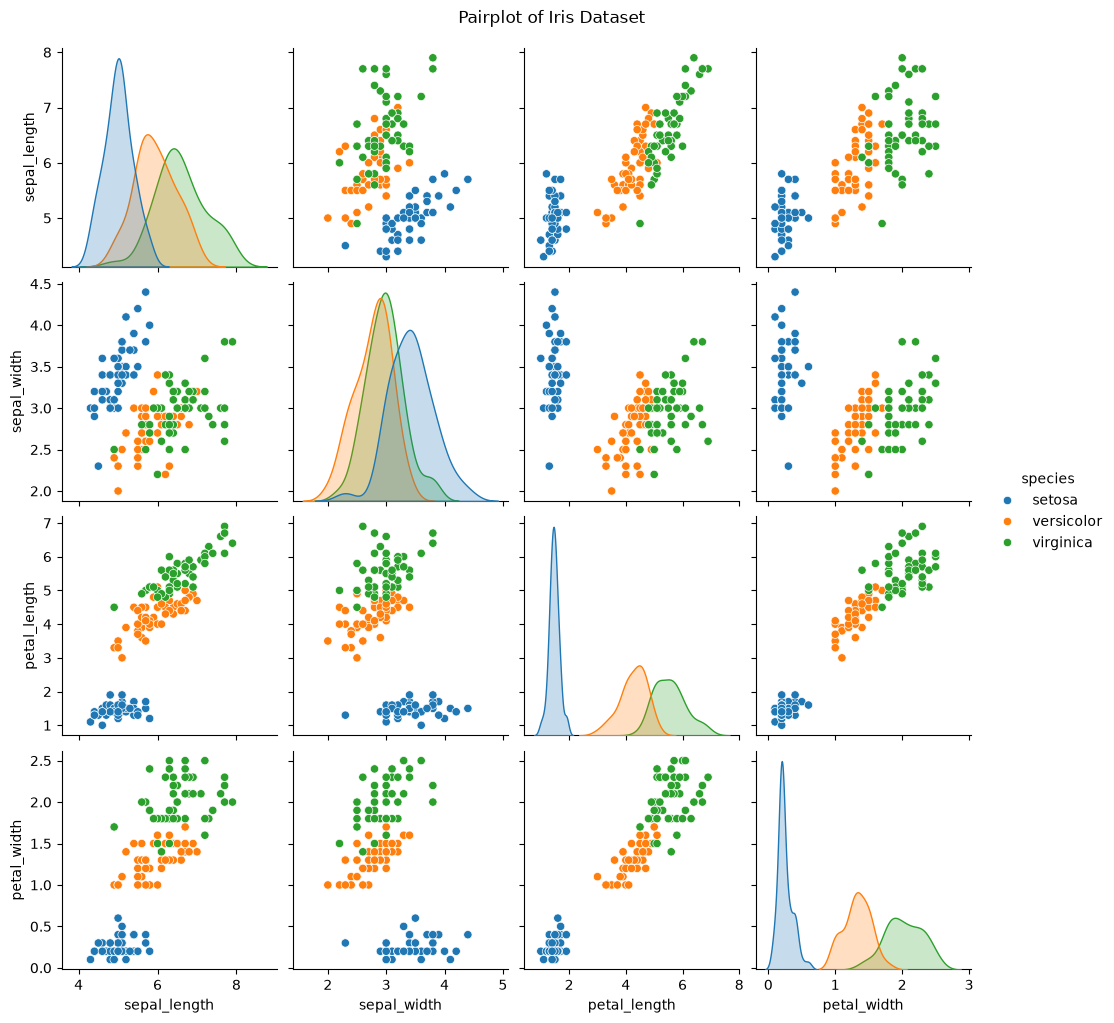

In [4]:
# Create pairplot to visualize relationships between features

sns.pairplot(df, hue='species')

plt.suptitle("Pairplot of Iris Dataset", y=1.02)

plt.show()

In [5]:
# Independent Features
X = df.drop('species', axis=1)

# Dependent Target
y = df['species']

print("Features (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

Features (X):


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target (y):


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (120, 4)
Testing Features: (30, 4)

Training Target: (120,)
Testing Target: (30,)


In [7]:
print("Training Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Class Distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing Class Distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [8]:
from sklearn.preprocessing import StandardScaler

In [9]:
# Create StandardScaler object
scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Original Training Data:")
display(X_train.head())

print("\nScaled Training Data:")
print(X_train_scaled[:5])

Original Training Data:


,sepal_length,sepal_width,petal_length,petal_width
8,4.4,2.9,1.4,0.2
106,4.9,2.5,4.5,1.7
76,6.8,2.8,4.8,1.4
9,4.9,3.1,1.5,0.1
89,5.5,2.5,4.0,1.3



Scaled Training Data:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


In [10]:
from sklearn.linear_model import LogisticRegression

# Create model
lr_model = LogisticRegression(max_iter=200)

# Train model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression Predictions:")
print(lr_predictions[:10])

Logistic Regression Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [11]:
from sklearn.tree import DecisionTreeClassifier


In [12]:
# Create Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train_scaled, y_train)

# Make predictions
dt_predictions = dt_model.predict(X_test_scaled)

print("Decision Tree Predictions:")
print(dt_predictions[:10])

Decision Tree Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [14]:
def evaluate_model(y_true, y_pred, model_name):

    print("\nModel:", model_name)

    print("Accuracy:",
          accuracy_score(y_true, y_pred))

    print("Precision:",
          precision_score(y_true, y_pred, average='weighted'))

    print("Recall:",
          recall_score(y_true, y_pred, average='weighted'))

    print("F1 Score:",
          f1_score(y_true, y_pred, average='weighted'))

    print("\nClassification Report:")

    print(classification_report(y_true, y_pred))

In [15]:
evaluate_model(
    y_test,
    lr_predictions,
    "Logistic Regression"
)


Model: Logistic Regression
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [16]:
evaluate_model(
    y_test,
    dt_predictions,
    "Decision Tree"
)


Model: Decision Tree
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [17]:
evaluate_model(
    y_test,
    dt_predictions,
    "Decision Tree"
)


Model: Decision Tree
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [18]:
from sklearn.metrics import confusion_matrix

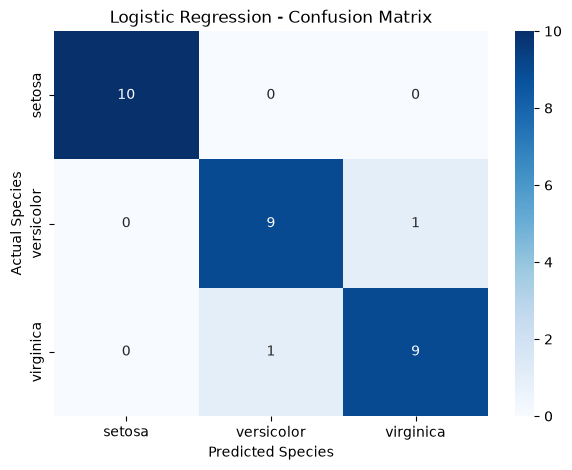

In [19]:
# Calculate confusion matrix
cm_lr = confusion_matrix(y_test, lr_predictions)

# Plot heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

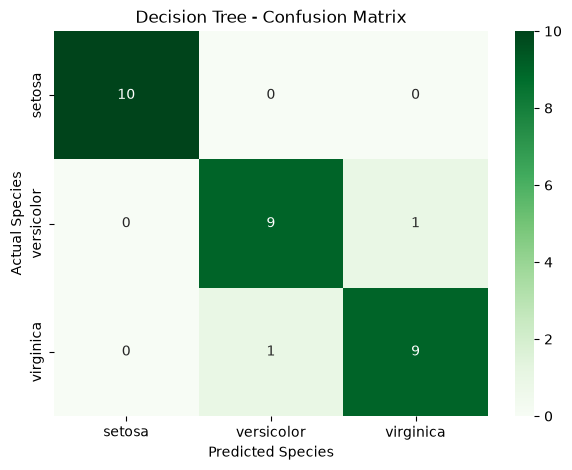

In [20]:
cm_dt = confusion_matrix(y_test, dt_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.show()

In [21]:
results = pd.DataFrame({

    'Model': ['Logistic Regression', 'Decision Tree'],

    'Accuracy': [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, dt_predictions)
    ],

    'Precision': [
        precision_score(y_test, lr_predictions, average='weighted'),
        precision_score(y_test, dt_predictions, average='weighted')
    ],

    'Recall': [
        recall_score(y_test, lr_predictions, average='weighted'),
        recall_score(y_test, dt_predictions, average='weighted')
    ],

    'F1 Score': [
        f1_score(y_test, lr_predictions, average='weighted'),
        f1_score(y_test, dt_predictions, average='weighted')
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


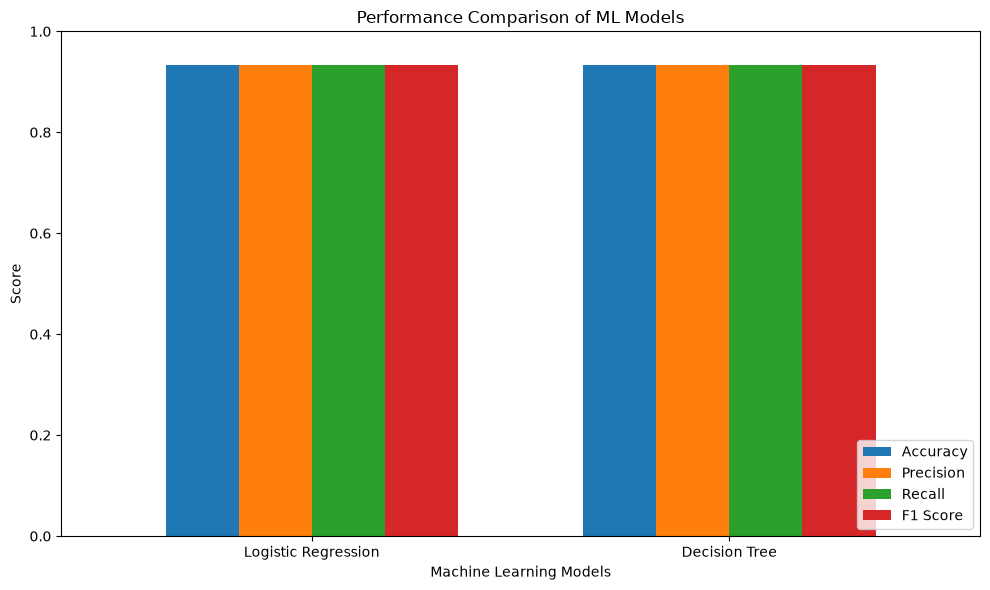

In [22]:
results_plot = results.set_index('Model')

results_plot.plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.7
)

plt.title("Performance Comparison of ML Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")

plt.xticks(rotation=0)
plt.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [23]:
# Identify the best performing model based on F1 Score

best_model = results.loc[
    results['F1 Score'].idxmax()
]

print("BEST PERFORMING MODEL")
print("---------------------")

print("Model:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1 Score:", round(best_model['F1 Score'], 4))

BEST PERFORMING MODEL
---------------------
Model: Logistic Regression
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1 Score: 0.9333
